# Reconstructing the FFT from a sound

Following [file://../Reading/MIT_J_Comp+Music-Rose-Hetrick.pdf](file://../Reading/MIT_J_Comp+Music-Rose-Hetrick.pdf)
    
<img src="../Imgs/fft_process.png" align='left'>


## Input sound: $~$ flu-e4-ord-mf.wav

In [13]:
from scipy.io import wavfile

In [14]:
insound = '../MiscSounds/flu-e4-ord-mf.wav'
insound = '../..//STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf.wav'

rate, sounddata = wavfile.read(insound)
sounddata

array([0, 0, 0, ..., 0, 0, 0], dtype=int16)

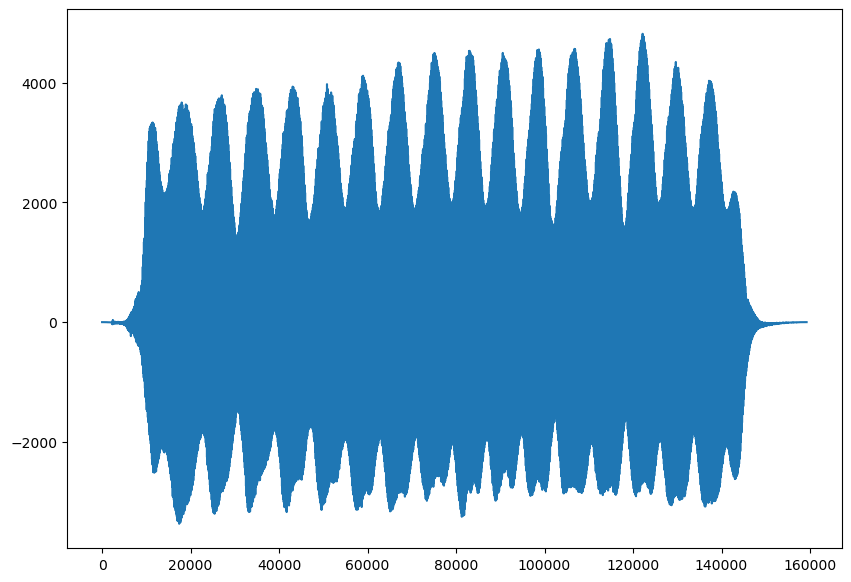

In [15]:
#%matplotlib inline

# This function is in my startup file: \Users\jhetrick\.ipython\profile_default\startup\mystartupcmds.py
def setPLTdisplay(n, m):
    plt.rcParams['figure.figsize'] = (n, m)

setPLTdisplay(10,7)

plt.plot(range(len(sounddata)), sounddata)

In [19]:
from pydub import AudioSegment
from pydub.playback import play

In [20]:
#sound = AudioSegment.from_file('../MiscSounds/flu-e4-ord-mf.wav')
sound = AudioSegment.from_file('../../OrchestrationEngine/Soundbank_McGill/Soundbank_WB/flu-e4-ord-mf.aif')

#WWBr-IsolatedSounds/Flu_aif
sound

In [6]:
len(sound.get_array_of_samples())

159232

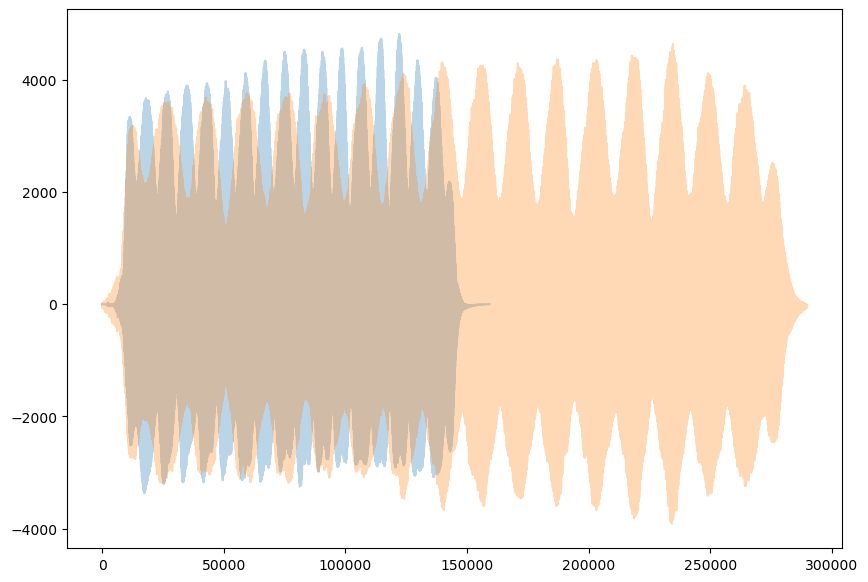

In [21]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.3)
plt.plot(range(len(sound.get_array_of_samples())), sound.get_array_of_samples(), alpha=0.3)

So, the data read by *scipy.io.wave.read()*, and the data gotten from the *pydub* (using sound = AudioSegment; sound.get_array_of_samples())

$$-\infty-$$

## FFT

In [22]:
from scipy.fftpack import fft, ifft

For this file, the start and stop indicies are


e4 | 26535 | 129800

In [23]:
begin, end = 26535, 129800

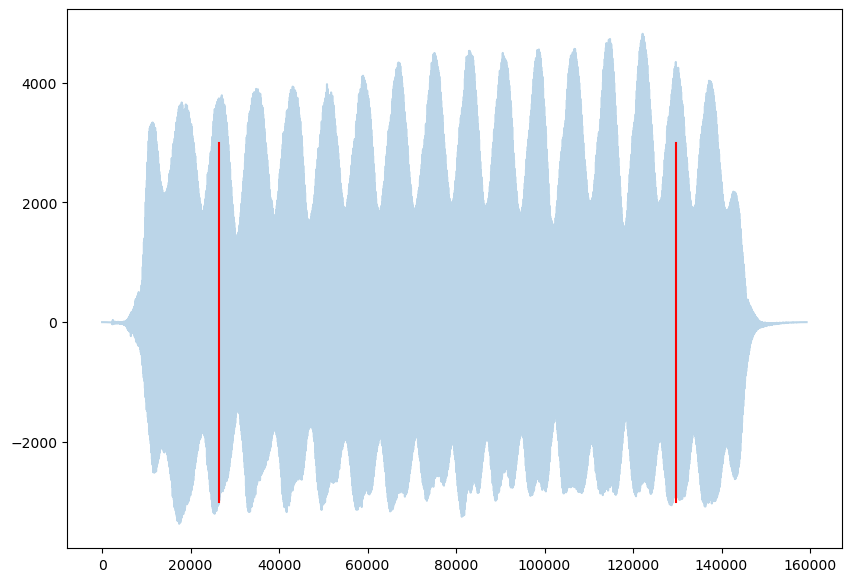

In [24]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.3)
plt.plot([begin,begin], [-3000,3000],'r')
plt.plot([end,end], [-3000,3000],'r')

In [25]:
hamwin = np.hamming(4096)

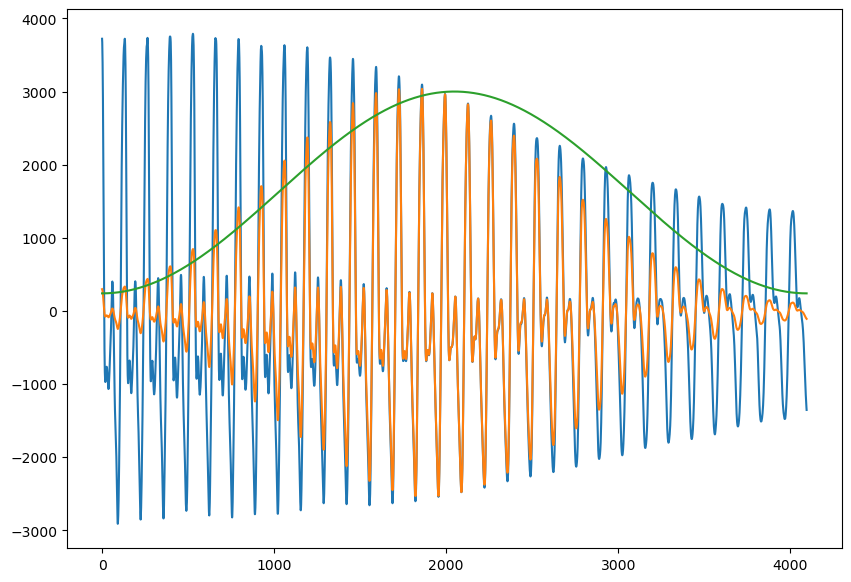

In [26]:
x = sounddata[begin:begin+4096]

plt.plot(range(4096), x)
plt.plot(range(4096), x*hamwin)
plt.plot(range(4096), 3000*hamwin)

In [27]:
n = 0
xf_ave = np.zeros(2048)

for i in range(begin, end-4096, 512):
    x = sounddata[i:i+4096]
    x = x * hamwin
    xf = fft(x)
    xf_ave += (np.absolute(xf)**2)[:2048]
    
    n+=1
    
xf_ave = np.sqrt(xf_ave)/n
xf_ave

array([8715.003, 3724.098,  256.203, ...,    7.435,    7.58 ,    7.395])

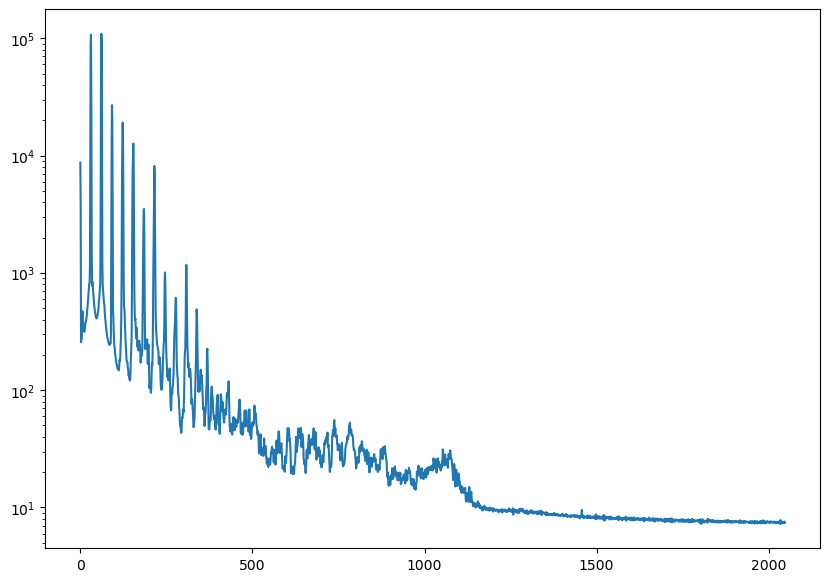

In [28]:
plt.plot(range(2048), xf_ave[:2048])
plt.yscale('log')

## Previous FFT:  $~$ flu-e4-ord-mf.nbb

In [32]:
srcfile = '../OldFFTBank/flu-e4-ord-mf.nbb'
nbbfft = np.fromfile(srcfile, dtype='float32')

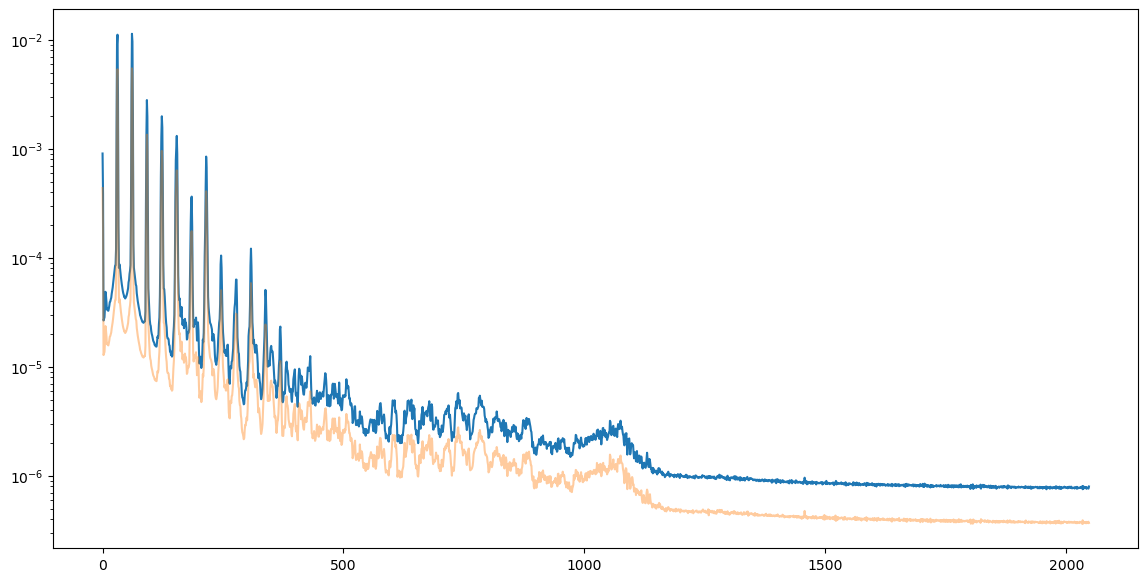

In [33]:
setPLTdisplay(14,7)

plt.plot(range(2048), nbbfft)
plt.plot(range(2048), xf_ave[:2048]/2e7, alpha=0.4)
plt.yscale('log')
#plt.xlim(0,500)

(0.0, 500.0)

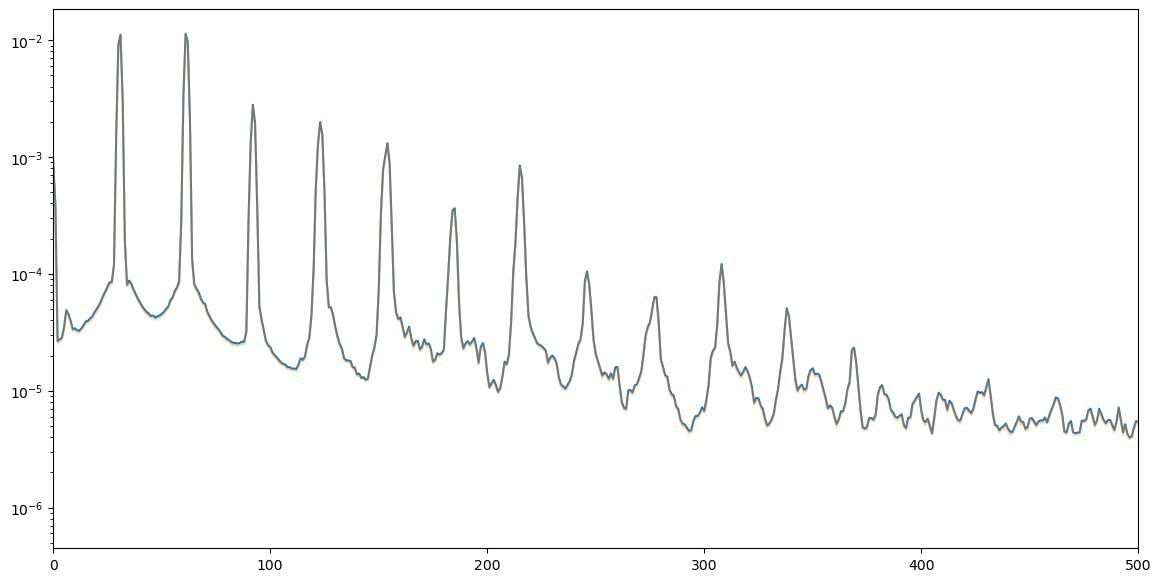

In [34]:
plt.plot(range(2048), nbbfft)
plt.plot(range(2048), xf_ave[:2048]/1e7, alpha=0.4)
plt.yscale('log')
plt.xlim(0,500)

the normalization coefficient is $\sim$ 1.e7

In [35]:
xf_ave[0]/nbbfft[0]

9634749.954282803

---

$$-\infty-$$

---

Another sound

In [38]:
instrument = 'cla-e5-ord-mf'
folder = 'Cla_aif'

sound = AudioSegment.from_file('../../STO/WWBr-IsolatedSounds/' + folder +'/'+ instrument + '.aif')
sounddata = sound.get_array_of_samples()

In [39]:
# e5	17070	163055
begin,end = 17070,163055

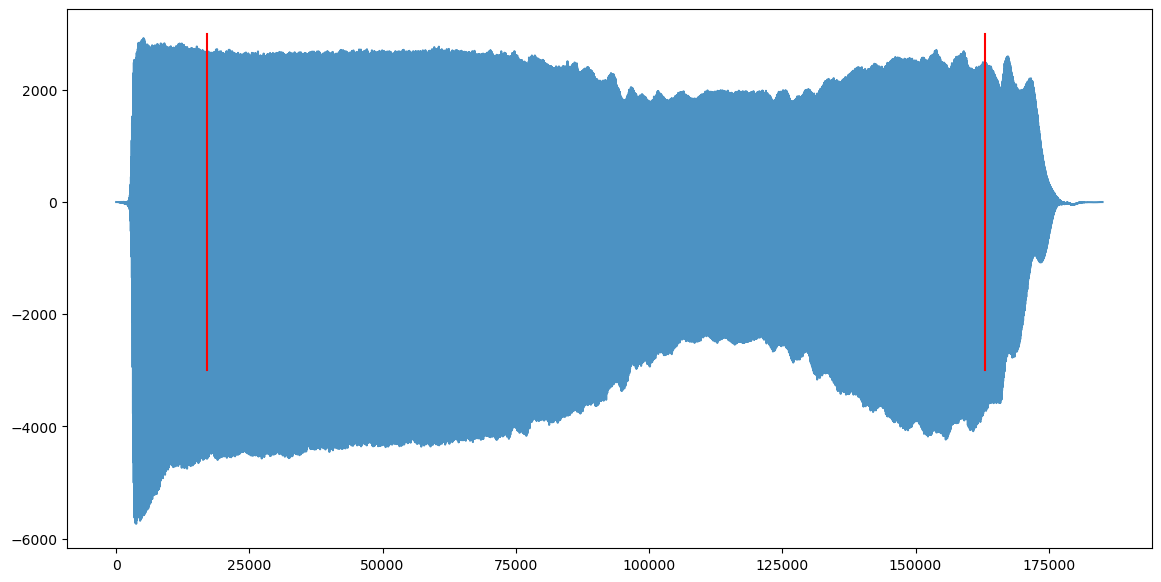

In [40]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.8)
plt.plot([begin,begin], [-3000,3000],'r')
plt.plot([end,end], [-3000,3000],'r')

In [47]:
n = 0
xf_ave = np.zeros(2048)

for i in range(begin, end-4096, 512):
    x = sounddata[i:i+4096]
    x = x * hamwin
    xf = fft(x)
    xf_ave += (np.absolute(xf)**2)[0:2048]
    n+=1
    
xf_ave = np.sqrt(xf_ave)/n
xf_ave

array([8547.828, 5333.436, 2013.195, ...,    5.842,    5.755,    5.677])

In [48]:
srcfile = '../OldFFTBank/' + instrument + '.nbb'
nbbfft = np.fromfile(srcfile, dtype='float32')

In [49]:
norm = xf_ave[0]/nbbfft[0]
norm

8108746.295057129

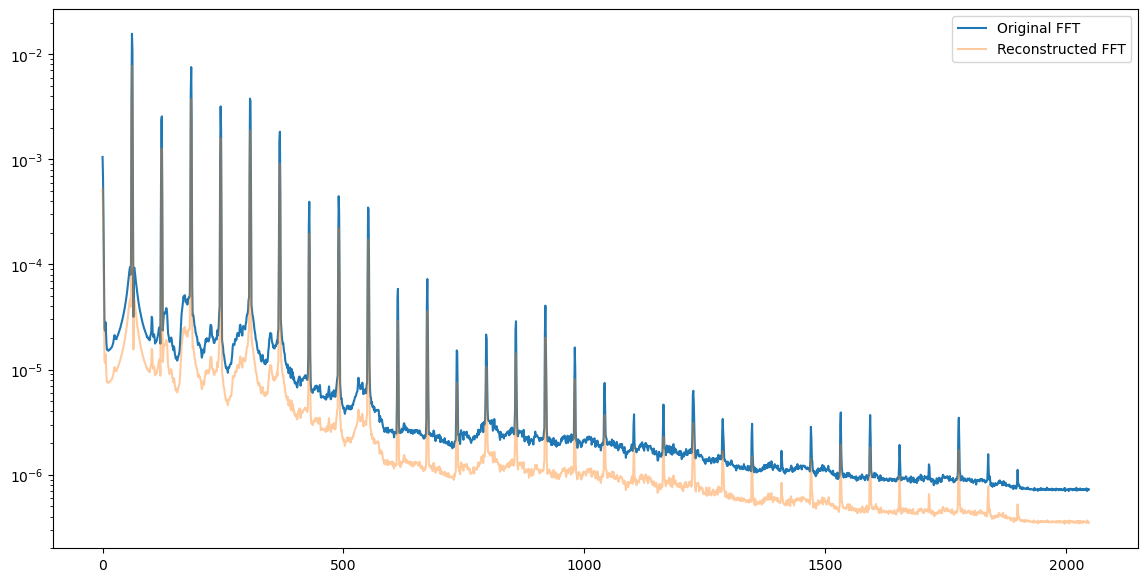

In [52]:
plt.plot(range(2048), nbbfft, label="Original FFT")
plt.plot(range(2048), xf_ave[:2048]/norm/2, alpha=0.4, label="Reconstructed FFT")
plt.yscale('log')
#plt.xlim(0,500)
plt.legend()

## Exact $~$ (up to the normalization $\sim$1e7)